In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configuración para mostrar más columnas
pd.set_option("display.max_columns", None)

# Configuración para mostrar números con 2 decimales
pd.set_option("display.float_format", "{:.2f}".format)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [2]:
DATASET_PATH = "../data/raw/amazon_delivery.csv"

df = pd.read_csv(DATASET_PATH)

print("Dataset cargado correctamente.")
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")

Dataset cargado correctamente.
Filas: 43,739
Columnas: 16


In [3]:
df.head()

,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Weather,Traffic,Vehicle,Area,Delivery_Time,Category
0,ialx566343618,37,4.90,22.75,75.89,22.77,75.91,2022-03-19,11:30:00,11:45:00,Sunny,High,motorcycle,Urban,120,Clothing
1,akqg208421122,34,4.50,12.91,77.68,13.04,77.81,2022-03-25,19:45:00,19:50:00,Stormy,Jam,scooter,Metropolitian,165,Electronics
2,njpu434582536,23,4.40,12.91,77.68,12.92,77.69,2022-03-19,08:30:00,08:45:00,Sandstorms,Low,motorcycle,Urban,130,Sports
3,rjto796129700,38,4.70,11.00,76.98,11.05,77.03,2022-04-05,18:00:00,18:10:00,Sunny,Medium,motorcycle,Metropolitian,105,Cosmetics
4,zguw716275638,32,4.60,12.97,80.25,13.01,80.29,2022-03-26,13:30:00,13:45:00,Cloudy,High,scooter,Metropolitian,150,Toys


In [4]:
df.tail()

,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Weather,Traffic,Vehicle,Area,Delivery_Time,Category
43734,jlxf819993117,30,4.80,26.90,75.79,26.91,75.80,2022-03-24,11:35:00,11:45:00,Windy,High,motorcycle,Metropolitian,160,Home
43735,aevx342135787,21,4.60,0.00,0.00,0.07,0.07,2022-02-16,19:55:00,20:10:00,Windy,Jam,motorcycle,Metropolitian,180,Jewelry
43736,xnek760674819,30,4.90,13.02,80.24,13.05,80.27,2022-03-11,23:50:00,00:05:00,Cloudy,Low,scooter,Metropolitian,80,Home
43737,cynl434665991,20,4.70,11.00,76.99,11.04,77.03,2022-03-07,13:35:00,13:40:00,Cloudy,High,motorcycle,Metropolitian,130,Kitchen
43738,nsyz997960170,23,4.90,23.35,85.33,23.43,85.41,2022-03-02,17:10:00,17:15:00,Fog,Medium,scooter,Metropolitian,180,Cosmetics


In [5]:
filas, columnas = df.shape

print(f"Número de envíos: {filas:,}")
print(f"Número de variables: {columnas}")

Número de envíos: 43,739
Número de variables: 16


In [6]:
print("Columnas del dataset:\n")

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Columnas del dataset:

1. Order_ID
2. Agent_Age
3. Agent_Rating
4. Store_Latitude
5. Store_Longitude
6. Drop_Latitude
7. Drop_Longitude
8. Order_Date
9. Order_Time
10. Pickup_Time
11. Weather
12. Traffic
13. Vehicle
14. Area
15. Delivery_Time
16. Category


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 43739 entries, 0 to 43738
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID         43739 non-null  str    
 1   Agent_Age        43739 non-null  int64  
 2   Agent_Rating     43685 non-null  float64
 3   Store_Latitude   43739 non-null  float64
 4   Store_Longitude  43739 non-null  float64
 5   Drop_Latitude    43739 non-null  float64
 6   Drop_Longitude   43739 non-null  float64
 7   Order_Date       43739 non-null  str    
 8   Order_Time       43739 non-null  str    
 9   Pickup_Time      43739 non-null  str    
 10  Weather          43648 non-null  str    
 11  Traffic          43739 non-null  str    
 12  Vehicle          43739 non-null  str    
 13  Area             43739 non-null  str    
 14  Delivery_Time    43739 non-null  int64  
 15  Category         43739 non-null  str    
dtypes: float64(5), int64(2), str(9)
memory usage: 5.3 MB


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Agent_Age,43739.00,29.57,5.82,15.00,25.00,30.00,35.00,50.00
Agent_Rating,43685.00,4.63,0.33,1.00,4.50,4.70,4.90,6.00
Store_Latitude,43739.00,17.21,7.76,-30.90,12.93,18.55,22.73,30.91
Store_Longitude,43739.00,70.66,21.48,-88.37,73.17,75.90,78.05,88.43
Drop_Latitude,43739.00,17.46,7.34,0.01,12.99,18.63,22.79,31.05
Drop_Longitude,43739.00,70.82,21.15,0.01,73.28,76.00,78.10,88.56
Delivery_Time,43739.00,124.91,51.92,10.00,90.00,125.00,160.00,270.00


In [9]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order_ID,43739,43739,ialx566343618,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Agent_Age,43739.00,NaN,NaN,NaN,29.57,5.82,15.00,25.00,30.00,35.00,50.00
Agent_Rating,43685.00,NaN,NaN,NaN,4.63,0.33,1.00,4.50,4.70,4.90,6.00
Store_Latitude,43739.00,NaN,NaN,NaN,17.21,7.76,-30.90,12.93,18.55,22.73,30.91
Store_Longitude,43739.00,NaN,NaN,NaN,70.66,21.48,-88.37,73.17,75.90,78.05,88.43
Drop_Latitude,43739.00,NaN,NaN,NaN,17.46,7.34,0.01,12.99,18.63,22.79,31.05
Drop_Longitude,43739.00,NaN,NaN,NaN,70.82,21.15,0.01,73.28,76.00,78.10,88.56
Order_Date,43739,44,2022-03-15,1141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Time,43739,177,21:55:00,460,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pickup_Time,43739,193,21:30:00,481,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
missing = pd.DataFrame({
    "Valores_faltantes": df.isnull().sum(),
    "Porcentaje": (df.isnull().sum() / len(df) * 100).round(2)
})

missing = missing[missing["Valores_faltantes"] > 0]

missing.sort_values("Valores_faltantes", ascending=False)

,Valores_faltantes,Porcentaje
Weather,91,0.21
Agent_Rating,54,0.12


In [11]:
total_missing = df.isnull().sum().sum()
total_cells = df.shape[0] * df.shape[1]

percentage_missing = (total_missing / total_cells) * 100

print(f"Total de valores faltantes: {total_missing:,}")
print(f"Porcentaje total de datos faltantes: {percentage_missing:.2f}%")

Total de valores faltantes: 145
Porcentaje total de datos faltantes: 0.02%


In [12]:
duplicated_orders = df["Order_ID"].duplicated().sum()

print(f"Order_ID duplicados: {duplicated_orders:,}")

Order_ID duplicados: 0


In [13]:
categorical_columns = [
    "Weather",
    "Traffic",
    "Vehicle",
    "Area",
    "Category"
]

for column in categorical_columns:
    print("=" * 50)
    print(column)
    print("=" * 50)
    print(df[column].value_counts(dropna=False))
    print()

Weather
Weather
Fog           7440
Stormy        7374
Cloudy        7288
Sandstorms    7245
Windy         7223
Sunny         7078
NaN             91
Name: count, dtype: int64

Traffic
Traffic
Low        14999
Jam        13725
Medium     10628
High        4296
NaN           91
Name: count, dtype: int64

Vehicle
Vehicle
motorcycle     25527
scooter        14639
van             3558
bicycle           15
Name: count, dtype: int64

Area
Area
Metropolitian     32698
Urban              9751
Other              1138
Semi-Urban          152
Name: count, dtype: int64

Category
Category
Electronics     2849
Books           2824
Jewelry         2802
Toys            2781
Skincare        2772
Snacks          2770
Outdoors        2747
Apparel         2726
Sports          2719
Grocery         2691
Pet Supplies    2690
Home            2685
Cosmetics       2677
Kitchen         2673
Clothing        2667
Shoes           2666
Name: count, dtype: int64



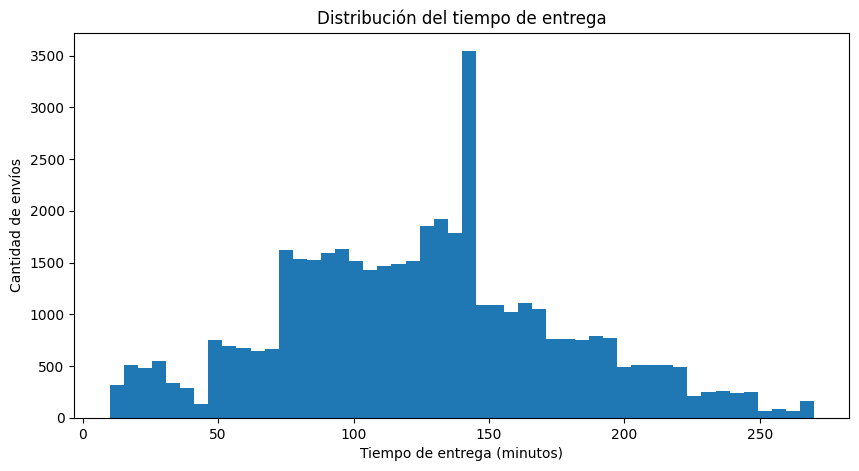

In [14]:
plt.figure(figsize=(10, 5))

plt.hist(df["Delivery_Time"].dropna(), bins=50)

plt.title("Distribución del tiempo de entrega")
plt.xlabel("Tiempo de entrega (minutos)")
plt.ylabel("Cantidad de envíos")

plt.show()

In [15]:
delivery_stats = df["Delivery_Time"].describe()

print(delivery_stats)

print(f"\nMediana: {df['Delivery_Time'].median():.2f} minutos")

count   43739.00
mean      124.91
std        51.92
min        10.00
25%        90.00
50%       125.00
75%       160.00
max       270.00
Name: Delivery_Time, dtype: float64

Mediana: 125.00 minutos


In [16]:
Q1 = df["Delivery_Time"].quantile(0.25)
Q3 = df["Delivery_Time"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Límite inferior: {lower_bound:.2f}")
print(f"Límite superior: {upper_bound:.2f}")

outliers = df[
    (df["Delivery_Time"] < lower_bound) |
    (df["Delivery_Time"] > upper_bound)
]

print(f"Posibles valores extremos: {len(outliers):,}")

Q1: 90.00
Q3: 160.00
IQR: 70.00
Límite inferior: -15.00
Límite superior: 265.00
Posibles valores extremos: 79


In [17]:
traffic_analysis = (
    df.groupby("Traffic")["Delivery_Time"]
      .agg(["count", "mean", "median", "min", "max"])
      .sort_values("mean", ascending=False)
)

traffic_analysis

,count,mean,median,min,max
Traffic,,,,,
Jam,13725,147.76,150.00,10,270
High,4296,129.42,135.00,10,270
Medium,10628,126.84,130.00,10,245
NaN,91,120.67,125.00,18,240
Low,14999,101.35,100.00,10,220


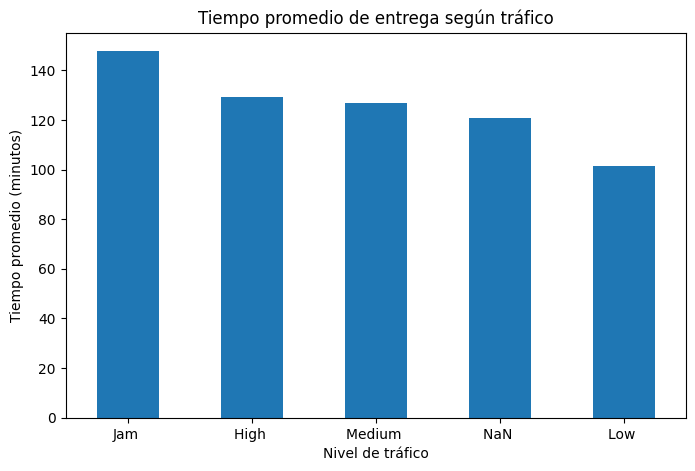

In [18]:
traffic_mean = (
    df.groupby("Traffic")["Delivery_Time"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

traffic_mean.plot(kind="bar")

plt.title("Tiempo promedio de entrega según tráfico")
plt.xlabel("Nivel de tráfico")
plt.ylabel("Tiempo promedio (minutos)")
plt.xticks(rotation=0)

plt.show()

In [19]:
weather_analysis = (
    df.groupby("Weather")["Delivery_Time"]
      .agg(["count", "mean", "median", "min", "max"])
      .sort_values("mean", ascending=False)
)

weather_analysis

,count,mean,median,min,max
Weather,,,,,
Cloudy,7288,138.29,140.00,10,270
Fog,7440,136.57,135.00,10,270
Windy,7223,123.66,125.00,10,270
Sandstorms,7245,123.24,125.00,10,270
Stormy,7374,123.21,125.00,10,270
Sunny,7078,103.66,100.00,10,270


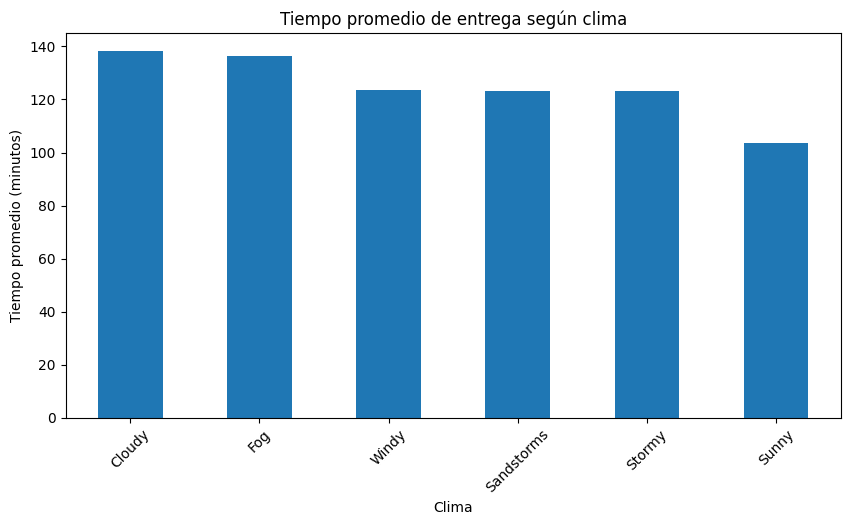

In [20]:
weather_mean = (
    df.groupby("Weather")["Delivery_Time"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

weather_mean.plot(kind="bar")

plt.title("Tiempo promedio de entrega según clima")
plt.xlabel("Clima")
plt.ylabel("Tiempo promedio (minutos)")
plt.xticks(rotation=45)

plt.show()

In [21]:
area_analysis = (
    df.groupby("Area")["Delivery_Time"]
      .agg(["count", "mean", "median", "min", "max"])
      .sort_values("mean", ascending=False)
)

area_analysis

,count,mean,median,min,max
Area,,,,,
Semi-Urban,152,238.55,245.00,44,270
Metropolitian,32698,129.70,130.00,10,270
Urban,9751,109.43,105.00,10,270
Other,1138,104.46,100.00,10,270


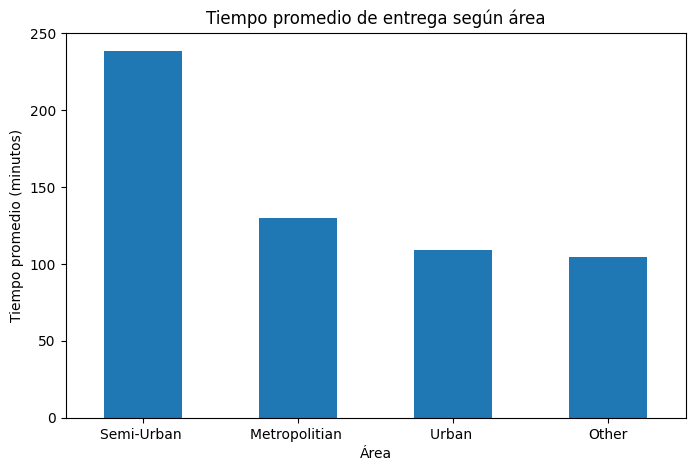

In [22]:
area_mean = (
    df.groupby("Area")["Delivery_Time"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

area_mean.plot(kind="bar")

plt.title("Tiempo promedio de entrega según área")
plt.xlabel("Área")
plt.ylabel("Tiempo promedio (minutos)")
plt.xticks(rotation=0)

plt.show()

In [23]:
vehicle_analysis = (
    df.groupby("Vehicle")["Delivery_Time"]
      .agg(["count", "mean", "median", "min", "max"])
      .sort_values("mean", ascending=False)
)

vehicle_analysis

,count,mean,median,min,max
Vehicle,,,,,
motorcycle,25527,131.03,130.00,10,270
bicycle,15,127.00,125.00,60,195
scooter,14639,116.36,115.00,10,245
van,3558,116.14,115.00,10,245


In [24]:
vehicle_analysis = (
    df.groupby("Vehicle")["Delivery_Time"]
      .agg(["count", "mean", "median", "min", "max"])
      .sort_values("mean", ascending=False)
)

vehicle_analysis

,count,mean,median,min,max
Vehicle,,,,,
motorcycle,25527,131.03,130.00,10,270
bicycle,15,127.00,125.00,60,195
scooter,14639,116.36,115.00,10,245
van,3558,116.14,115.00,10,245


In [25]:
category_analysis = (
    df.groupby("Category")["Delivery_Time"]
      .agg(["count", "mean", "median", "min", "max"])
      .sort_values("mean", ascending=False)
)

category_analysis

,count,mean,median,min,max
Category,,,,,
Cosmetics,2677,132.90,130.00,50,270
Kitchen,2673,132.33,130.00,50,270
Sports,2719,132.25,130.00,50,270
Apparel,2726,132.05,130.00,50,270
Skincare,2772,132.03,130.00,50,270
Snacks,2770,131.90,130.00,50,270
Pet Supplies,2690,131.29,130.00,50,270
Shoes,2666,131.15,130.00,50,270
Outdoors,2747,131.06,125.00,50,270


In [26]:
numeric_columns = [
    "Agent_Age",
    "Agent_Rating",
    "Store_Latitude",
    "Store_Longitude",
    "Drop_Latitude",
    "Drop_Longitude",
    "Delivery_Time"
]

correlation_matrix = df[numeric_columns].corr()

correlation_matrix

,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Delivery_Time
Agent_Age,1.00,-0.07,-0.00,-0.01,0.00,-0.00,0.25
Agent_Rating,-0.07,1.00,-0.01,-0.01,-0.01,-0.01,-0.29
Store_Latitude,-0.00,-0.01,1.00,0.66,0.93,0.64,0.02
Store_Longitude,-0.01,-0.01,0.66,1.00,0.68,0.98,0.01
Drop_Latitude,0.00,-0.01,0.93,0.68,1.00,0.69,0.02
Drop_Longitude,-0.00,-0.01,0.64,0.98,0.69,1.00,0.01
Delivery_Time,0.25,-0.29,0.02,0.01,0.02,0.01,1.00


In [27]:
correlation_with_delivery = (
    correlation_matrix["Delivery_Time"]
    .drop("Delivery_Time")
    .sort_values(key=abs, ascending=False)
)

correlation_with_delivery

Agent_Rating      -0.29
Agent_Age          0.25
Store_Latitude     0.02
Drop_Latitude      0.02
Drop_Longitude     0.01
Store_Longitude    0.01
Name: Delivery_Time, dtype: float64

In [28]:
df["Order_Time_Parsed"] = pd.to_datetime(
    df["Order_Time"],
    format="%H:%M:%S",
    errors="coerce"
)

df["Order_Hour"] = df["Order_Time_Parsed"].dt.hour

df[["Order_Time", "Order_Hour"]].head()

,Order_Time,Order_Hour
0,11:30:00,11.00
1,19:45:00,19.00
2,08:30:00,8.00
3,18:00:00,18.00
4,13:30:00,13.00


In [29]:
hour_analysis = (
    df.groupby("Order_Hour")["Delivery_Time"]
      .agg(["count", "mean", "median"])
      .sort_index()
)

hour_analysis

,count,mean,median
Order_Hour,,,
0.00,429,103.64,105.00
8.00,1810,93.04,90.00
9.00,1934,92.52,90.00
10.00,1980,93.02,90.00
11.00,1950,125.41,130.00
12.00,888,128.49,132.50
13.00,779,131.40,135.00
14.00,785,130.36,135.00
15.00,871,109.94,115.00


In [30]:
hour_analysis = (
    df.groupby("Order_Hour")["Delivery_Time"]
      .agg(["count", "mean", "median"])
      .sort_index()
)

hour_analysis

,count,mean,median
Order_Hour,,,
0.00,429,103.64,105.00
8.00,1810,93.04,90.00
9.00,1934,92.52,90.00
10.00,1980,93.02,90.00
11.00,1950,125.41,130.00
12.00,888,128.49,132.50
13.00,779,131.40,135.00
14.00,785,130.36,135.00
15.00,871,109.94,115.00


In [31]:
def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Calcula la distancia aproximada entre dos puntos
    geográficos utilizando la fórmula de Haversine.
    
    Retorna la distancia en kilómetros.
    """
    
    R = 6371  # Radio de la Tierra en kilómetros

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

In [32]:
df["Distance_KM"] = haversine_distance(
    df["Store_Latitude"],
    df["Store_Longitude"],
    df["Drop_Latitude"],
    df["Drop_Longitude"]
)

df["Distance_KM"].describe()

count   43739.00
mean       38.56
std       534.56
min         1.47
25%         4.66
50%         9.22
75%        13.68
max     19692.67
Name: Distance_KM, dtype: float64

In [33]:
distance_correlation = df[
    ["Distance_KM", "Delivery_Time"]
].corr()

distance_correlation

,Distance_KM,Delivery_Time
Distance_KM,1.00,-0.00
Delivery_Time,-0.00,1.00


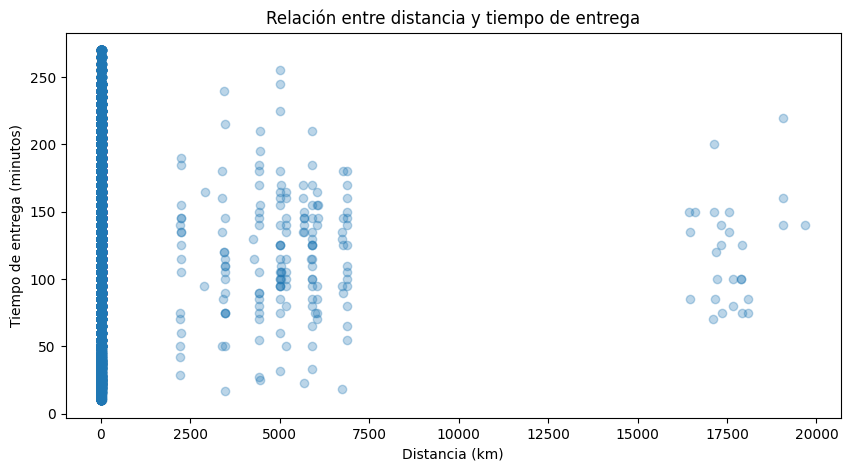

In [34]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df["Distance_KM"],
    df["Delivery_Time"],
    alpha=0.3
)

plt.xlabel("Distancia (km)")
plt.ylabel("Tiempo de entrega (minutos)")
plt.title("Relación entre distancia y tiempo de entrega")

plt.show()

In [35]:
df["Distance_KM"].describe(percentiles=[
    0.01,
    0.05,
    0.25,
    0.50,
    0.75,
    0.95,
    0.99
])

count   43739.00
mean       38.56
std       534.56
min         1.47
1%          1.49
5%          1.54
25%         4.66
50%         9.22
75%        13.68
95%        20.07
99%        20.85
max     19692.67
Name: Distance_KM, dtype: float64